<a href="https://colab.research.google.com/github/ShamaimI/ANN-DL/blob/main/LAB4_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task 1: Data and Weight Setup
Topic: Random colour data, a 10 x 10 grid of neuron weights, inspecting both

Task 1 (a)
Write code to generate 200 random colors (each with R, G, B values between 0 and 1) using NumPy.

Generated 200 random colours, shape: (200, 3)

First 5 colours (R, G, B):
[[0.309 0.88  0.243]
 [0.208 0.846 0.141]
 [0.305 0.138 0.527]
 [0.925 0.534 0.27 ]
 [0.951 0.422 0.261]]


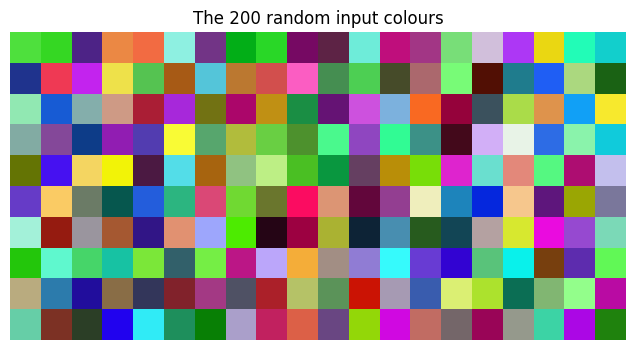

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 4.5)

SEED = 58                       # from roll number FA23-BAI-038, keeps every run the same
rng = np.random.default_rng(SEED)

N_SAMPLES = 200
data = rng.random((N_SAMPLES, 3))   # one row per colour: [R, G, B], each value in [0, 1)

print("Generated", N_SAMPLES, "random colours, shape:", data.shape)
print("\nFirst 5 colours (R, G, B):")
print(np.round(data[:5], 3))

# Quick look at all 200 colours as a 10 x 20 strip of swatches
plt.figure(figsize=(8, 4))
plt.imshow(data.reshape(10, 20, 3))
plt.title("The 200 random input colours")
plt.axis("off")
plt.show()

Task 1 (b)
Write code to create a 10 x 10 grid of neurons, where each neuron has a random weight vector of 3 values.

In [2]:
GRID_SIZE = 10

# weights[row, col] is the 3-value weight vector (R, G, B) of the neuron at that position
weights = rng.random((GRID_SIZE, GRID_SIZE, 3))

print("Grid of neurons :", GRID_SIZE, "x", GRID_SIZE, "=", GRID_SIZE * GRID_SIZE, "neurons")
print("Weights shape   :", weights.shape, "-> (rows, columns, values per neuron)")
print("Neuron (0, 0)   :", np.round(weights[0, 0], 3))
print("Neuron (9, 9)   :", np.round(weights[9, 9], 3))

Grid of neurons : 10 x 10 = 100 neurons
Weights shape   : (10, 10, 3) -> (rows, columns, values per neuron)
Neuron (0, 0)   : [0.885 0.251 0.658]
Neuron (9, 9)   : [0.9   0.852 0.047]


Task 1 (c)
Display the initial weight grid as an image using plt.imshow().

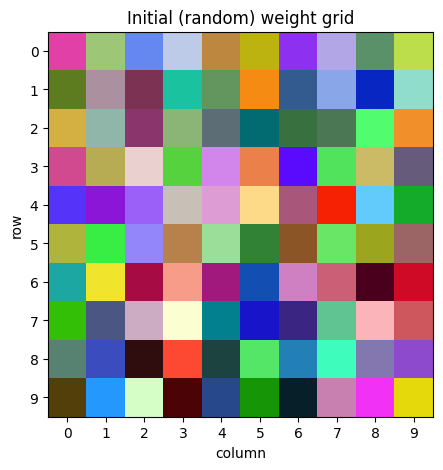

In [3]:
plt.figure(figsize=(5, 5))
plt.imshow(weights)
plt.title("Initial (random) weight grid")
plt.xticks(range(GRID_SIZE))
plt.yticks(range(GRID_SIZE))
plt.xlabel("column")
plt.ylabel("row")
plt.show()

Task 1 (d)
Write code to print the shape, minimum value and maximum value of both the data and the weight grid.

In [4]:
# Muhammad Salman Khan | FA23-BAI-038 | Task 1 (d)
print(f"{'':12}{'shape':>14}{'min':>10}{'max':>10}")
for label, arr in [("data", data), ("weights", weights)]:
    print(f"{label:12}{str(arr.shape):>14}{arr.min():>10.4f}{arr.max():>10.4f}")

                     shape       min       max
data              (200, 3)    0.0040    0.9994
weights        (10, 10, 3)    0.0035    0.9991



Task 2: Distance Calculation
Topic: Euclidean distance between a sample and every neuron, vectorized with NumPy

Task 2 (a)
Write a function euclidean_distance(a, b) that returns the distance between two vectors.

In [5]:
def euclidean_distance(a, b):
    """Euclidean distance between a and b.

    Works on the last axis, so it also gives one distance per neuron when
    a is the whole (rows, cols, 3) weight grid and b is a single sample.
    """
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return np.sqrt(np.sum((a - b) ** 2, axis=-1))


# Check against a case we can work out by hand: sqrt(1 + 1 + 1) = sqrt(3)
print("distance([0,0,0], [1,1,1]) =", round(euclidean_distance([0, 0, 0], [1, 1, 1]), 6))
print("sqrt(3)                    =", round(np.sqrt(3), 6))
print("np.linalg.norm check       =", round(np.linalg.norm(np.array([1, 1, 1])), 6))

distance([0,0,0], [1,1,1]) = 1.732051
sqrt(3)                    = 1.732051
np.linalg.norm check       = 1.732051


Task 2 (b)
Pick one random sample from the data and compute its distance to every neuron in the grid using vectorized NumPy code (no nested loops). The result must be a 10 x 10 array.

In [6]:
sample_idx = int(rng.integers(N_SAMPLES))
x = data[sample_idx]

# Broadcasting: (10, 10, 3) - (3,) -> (10, 10, 3), then sum over the last axis -> (10, 10)
distances = euclidean_distance(weights, x)

print("Picked sample #", sample_idx, "with colour", np.round(x, 3))
print("Distance array shape:", distances.shape)
print("\nDistances (rounded to 2 d.p.):")

Picked sample # 69 with colour [0.302 0.571 0.177]
Distance array shape: (10, 10)

Distances (rounded to 2 d.p.):


Task 2 (c)
Display the distance array as a heatmap with a colorbar.

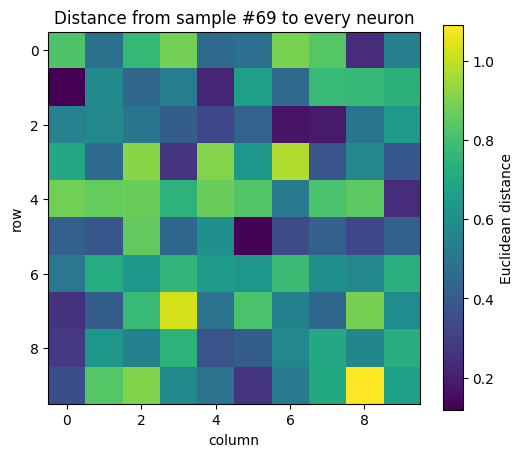

In [7]:
plt.figure(figsize=(6, 5))
plt.imshow(distances, cmap="viridis")
plt.colorbar(label="Euclidean distance")
plt.title(f"Distance from sample #{sample_idx} to every neuron")
plt.xlabel("column")
plt.ylabel("row")
plt.show()

Task 2 (d)
Write code to print the smallest distance and the row and column where it occurs.

In [8]:
min_row, min_col = np.unravel_index(np.argmin(distances), distances.shape)

print("Smallest distance :", round(float(distances[min_row, min_col]), 4))
print("Found at          : row", int(min_row), ", column", int(min_col))
print("Neuron weights    :", np.round(weights[min_row, min_col], 3))
print("Sample colour     :", np.round(x, 3))

Smallest distance : 0.1177
Found at          : row 1 , column 0
Neuron weights    : [0.365 0.487 0.123]
Sample colour     : [0.302 0.571 0.177]


Task 3: Finding the Winner (BMU)
Topic: Best Matching Unit (BMU), marking it on the grid, hit map of all samples

Task 3 (a)
Write a function find_bmu(weights, x) that returns the (row, column) of the Best Matching Unit.
Task 3 (b)
Call the function on 5 different samples and print the results in a neat format: sample number, BMU position, distance.
Task 3 (c)
Display the weight grid and mark the BMU of one sample with a red marker using plt.scatter().
Task 3 (d)
Find the BMU of all 200 samples, count how many samples land on each neuron, and display the counts as a 10 x 10 heatmap (a hit map).


BMU of sample # 69 -> (1, 0)
  Sample |  BMU (row, col)  | Distance
----------------------------------------
     146 |      (5, 7)      |   0.1376
      72 |      (8, 7)      |   0.1653
     161 |      (8, 6)      |   0.0630
     152 |      (8, 7)      |   0.2515
       4 |      (3, 5)      |   0.0938


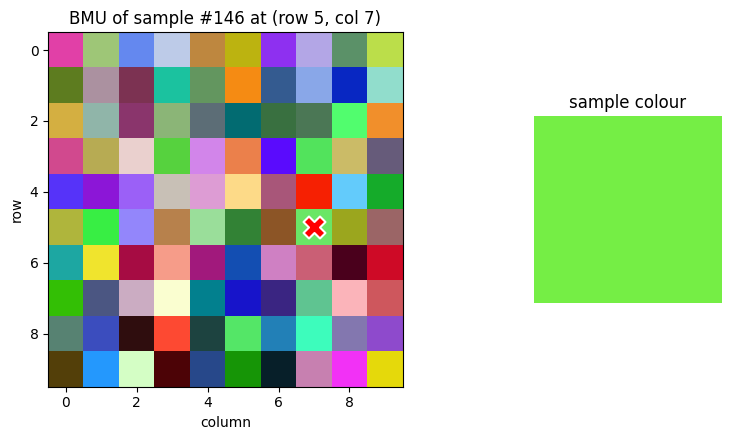

Total hits      : 200 (should be 200 )
Neurons used    : 79 of 100
Busiest neuron  : (np.int64(3), np.int64(3)) with 7 samples


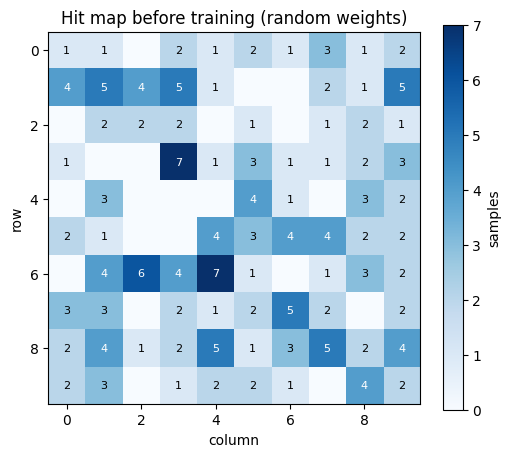

In [9]:
def find_bmu(weights, x):
    """Return (row, column) of the neuron whose weights are closest to sample x."""
    dist = euclidean_distance(weights, x)
    row, col = np.unravel_index(np.argmin(dist), dist.shape)
    return int(row), int(col)


# Should agree with the minimum found by hand in Task 2 (d)
print("BMU of sample #", sample_idx, "->", find_bmu(weights, x))

five_samples = rng.choice(N_SAMPLES, size=5, replace=False)

print(f"{'Sample':>8} | {'BMU (row, col)':^16} | {'Distance':>8}")
print("-" * 40)
for s in five_samples:
    r, c = find_bmu(weights, data[s])
    d = euclidean_distance(weights[r, c], data[s])
    print(f"{s:>8} | {str((r, c)):^16} | {d:>8.4f}")
demo_sample = int(five_samples[0])
bmu_r, bmu_c = find_bmu(weights, data[demo_sample])

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), gridspec_kw={"width_ratios": [4, 1]})

axes[0].imshow(weights)
# imshow puts columns on the x-axis and rows on the y-axis
axes[0].scatter(bmu_c, bmu_r, s=250, c="red", marker="X", edgecolors="white", linewidths=1.5)
axes[0].set_title(f"BMU of sample #{demo_sample} at (row {bmu_r}, col {bmu_c})")
axes[0].set_xlabel("column")
axes[0].set_ylabel("row")

axes[1].imshow(data[demo_sample].reshape(1, 1, 3))
axes[1].set_title("sample colour")
axes[1].axis("off")
plt.tight_layout()
plt.show()

hit_map = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)
for sample in data:
    r, c = find_bmu(weights, sample)
    hit_map[r, c] += 1

print("Total hits      :", hit_map.sum(), "(should be", N_SAMPLES, ")")
print("Neurons used    :", np.count_nonzero(hit_map), "of", GRID_SIZE * GRID_SIZE)
print("Busiest neuron  :", np.unravel_index(hit_map.argmax(), hit_map.shape), "with", hit_map.max(), "samples")

plt.figure(figsize=(6, 5))
plt.imshow(hit_map, cmap="Blues")
plt.colorbar(label="samples")
for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        if hit_map[r, c]:
            plt.text(c, r, hit_map[r, c], ha="center", va="center", fontsize=8,
                     color="white" if hit_map[r, c] > hit_map.max() / 2 else "black")
plt.title("Hit map before training (random weights)")
plt.xlabel("column")
plt.ylabel("row")
plt.show()


Task 4: Neighborhood Function
Topic: Gaussian and bubble neighbourhoods around the BMU

Task 4 (a)
Write a function neighborhood(grid_size, bmu, radius) that returns a 2D array of Gaussian values h, equal to 1 at the BMU and smaller farther away.
Task 4 (b)
Plot the output for a BMU at (5, 5) with radius 1, 3 and 5 in three side-by-side subplots.
Task 4 (c)
Write a second version of the function that sets h to 0 for every neuron farther than the radius (a bubble neighborhood), and plot it next to the Gaussian version.
Task 4 (d)
Write code to print the value of h at the BMU and at a neuron 3 steps away, using radius 2.

shape          : (10, 10)
h at BMU (5,5) : 1.0
h at (5,6)     : 0.8825   (1 step away)
h at (5,9)     : 0.1353   (4 steps away)


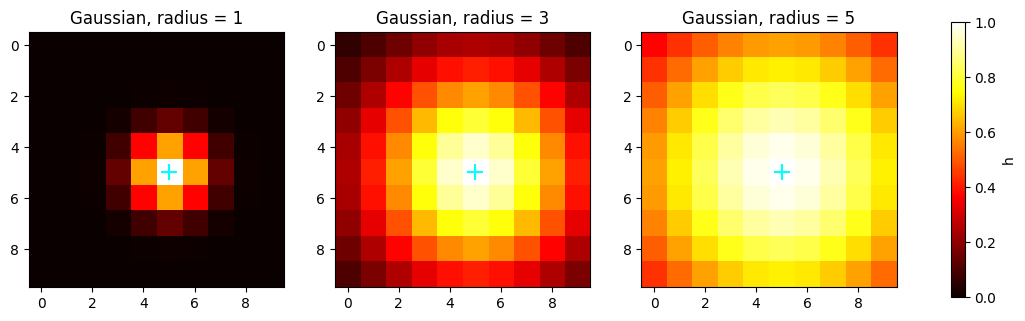

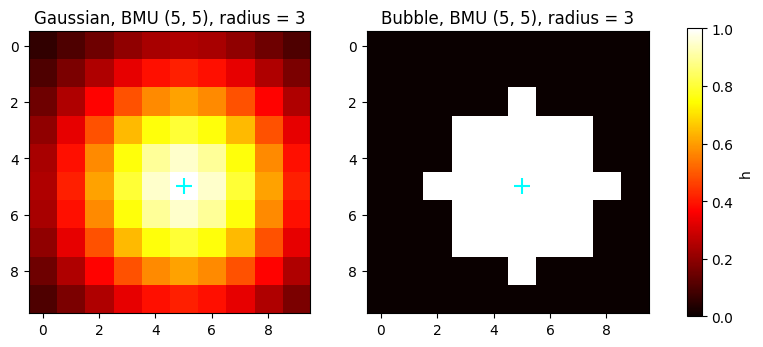

radius = 2
Gaussian h at BMU (5, 5)          : 1.0000
Gaussian h at (5, 8) (3 steps)    : 0.3247   = exp(-9 / 8)
Bubble   h at BMU (5, 5)          : 1.0000
Bubble   h at (5, 8) (3 steps)    : 0.0000   (3 > radius, so 0)


In [10]:
def neighborhood(grid_size, bmu, radius):
    """Gaussian neighbourhood: h = exp(-d^2 / (2 * radius^2)), where d is the grid
    distance of each neuron from the BMU. h = 1 at the BMU and falls off with distance."""
    rows, cols = np.indices((grid_size, grid_size))
    d_squared = (rows - bmu[0]) ** 2 + (cols - bmu[1]) ** 2
    return np.exp(-d_squared / (2 * radius ** 2))


h = neighborhood(10, (5, 5), 2)
print("shape          :", h.shape)
print("h at BMU (5,5) :", h[5, 5])
print("h at (5,6)     :", round(h[5, 6], 4), "  (1 step away)")
print("h at (5,9)     :", round(h[5, 9], 4), "  (4 steps away)")
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, radius in zip(axes, [1, 3, 5]):
    im = ax.imshow(neighborhood(10, (5, 5), radius), cmap="hot", vmin=0, vmax=1)
    ax.scatter(5, 5, c="cyan", marker="+", s=120)
    ax.set_title(f"Gaussian, radius = {radius}")
fig.colorbar(im, ax=axes, shrink=0.85, label="h")
plt.show()

def neighborhood_bubble(grid_size, bmu, radius):
    """Bubble neighbourhood: h = 1 inside the radius and 0 for every neuron farther away."""
    rows, cols = np.indices((grid_size, grid_size))
    distance = np.sqrt((rows - bmu[0]) ** 2 + (cols - bmu[1]) ** 2)
    return (distance <= radius).astype(float)


radius = 3
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, (title, func) in zip(axes, [("Gaussian", neighborhood), ("Bubble", neighborhood_bubble)]):
    im = ax.imshow(func(10, (5, 5), radius), cmap="hot", vmin=0, vmax=1)
    ax.scatter(5, 5, c="cyan", marker="+", s=120)
    ax.set_title(f"{title}, BMU (5, 5), radius = {radius}")
fig.colorbar(im, ax=axes, shrink=0.85, label="h")
plt.show()
bmu = (5, 5)
far = (5, 8)                     # same row, 3 columns away -> 3 steps from the BMU
radius = 2

h_gauss = neighborhood(10, bmu, radius)
h_bubble = neighborhood_bubble(10, bmu, radius)

print(f"radius = {radius}")
print(f"Gaussian h at BMU {bmu}          : {h_gauss[bmu]:.4f}")
print(f"Gaussian h at {far} (3 steps)    : {h_gauss[far]:.4f}   = exp(-9 / 8)")
print(f"Bubble   h at BMU {bmu}          : {h_bubble[bmu]:.4f}")
print(f"Bubble   h at {far} (3 steps)    : {h_bubble[far]:.4f}   (3 > radius, so 0)")


Task 5: One Weight Update Step
Topic: Applying a single SOM update and checking its effect

Task 5 (a)
Write a function update_weights(weights, x, bmu, learning_rate, radius) that applies one SOM update and returns the new weights.
Task 5 (b)
Apply the function once and show the weight grid before and after in two subplots.
Task 5 (c)
Write code to compute and print the total absolute change in the weights caused by this single update.
Task 5 (d)
Write code to print the distance between the BMU and the sample before and after the update, and confirm with an if statement that it decreased.

BMU weights after lr = 1 update: [0.309  0.8798 0.2431]
Sample                         : [0.309  0.8798 0.2431]


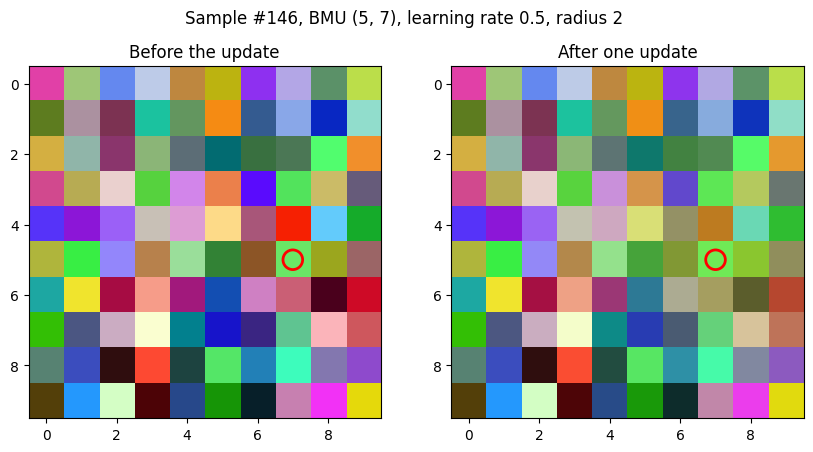

Total absolute change in all weights : 10.7498
Largest change of a single value     : 0.3628
Change at the BMU (sum of 3 values)  : 0.1001
Neurons that changed by > 0.01       : 70 of 100
Distance BMU <-> sample before : 0.1376
Distance BMU <-> sample after  : 0.0688
Ratio after / before           : 0.5 (expected 1 - lr * h = 1 - 0.5 * 1 = 0.5)

Confirmed: the update moved the BMU closer to the sample.


In [11]:
def update_weights(weights, x, bmu, learning_rate, radius):
    """One SOM step: every neuron moves towards x by learning_rate * h * (x - w).
    Neurons near the BMU (large h) move a lot, far ones barely move.
    Returns a new array; the input weights are left unchanged."""
    h = neighborhood(weights.shape[0], bmu, radius)
    return weights + learning_rate * h[:, :, np.newaxis] * (x - weights)


# Small check: with learning_rate = 1 the BMU takes exactly the sample's value
test_bmu = find_bmu(weights, data[0])
w_test = update_weights(weights, data[0], test_bmu, learning_rate=1.0, radius=1)
print("BMU weights after lr = 1 update:", np.round(w_test[test_bmu], 4))
print("Sample                         :", np.round(data[0], 4))
x_upd = data[demo_sample]
bmu_upd = find_bmu(weights, x_upd)
LR_DEMO, RADIUS_DEMO = 0.5, 2

weights_before = weights.copy()
weights_after = update_weights(weights_before, x_upd, bmu_upd, LR_DEMO, RADIUS_DEMO)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
for ax, w, title in [(axes[0], weights_before, "Before the update"), (axes[1], weights_after, "After one update")]:
    ax.imshow(w)
    ax.scatter(bmu_upd[1], bmu_upd[0], s=200, facecolors="none", edgecolors="red", linewidths=2)
    ax.set_title(title)
fig.suptitle(f"Sample #{demo_sample}, BMU {bmu_upd}, learning rate {LR_DEMO}, radius {RADIUS_DEMO}")
plt.show()
change = np.abs(weights_after - weights_before)

print("Total absolute change in all weights :", round(change.sum(), 4))
print("Largest change of a single value     :", round(change.max(), 4))
print("Change at the BMU (sum of 3 values)  :", round(change[bmu_upd].sum(), 4))
print("Neurons that changed by > 0.01       :", int((change.sum(axis=2) > 0.01).sum()), "of", GRID_SIZE * GRID_SIZE)
dist_before = euclidean_distance(weights_before[bmu_upd], x_upd)
dist_after = euclidean_distance(weights_after[bmu_upd], x_upd)

print("Distance BMU <-> sample before :", round(dist_before, 4))
print("Distance BMU <-> sample after  :", round(dist_after, 4))
print("Ratio after / before           :", round(dist_after / dist_before, 4),
      f"(expected 1 - lr * h = 1 - {LR_DEMO} * 1 = {1 - LR_DEMO})")

if dist_after < dist_before:
    print("\nConfirmed: the update moved the BMU closer to the sample.")
else:
    print("\nSomething is wrong: the distance did not decrease.")

Task 6: Training Loop
Topic: Full SOM training with exponentially decaying learning rate and radius

Task 6 (a)
Write a function train_som(data, grid_size, iterations, lr_start, radius_start) that runs the full training and returns the trained weights. The learning rate and radius must shrink with every iteration using exponential decay.
Task 6 (b)
Inside the loop, store the learning rate and radius every 100 iterations in two lists.
Task 6 (c)
Plot both lists on one line graph with a legend.
Task 6 (d)
Show the initial and trained weight grids side by side, and save the figure as task6_result.png.


Trained a 10 x 10 SOM for 5000 iterations
Trained weights shape: (10, 10, 3)
Values stored: 50 (one every 100 of 5000 iterations)
Learning rate: first 0.5 -> last 0.1877
Radius       : first 5.0 -> last 0.5236


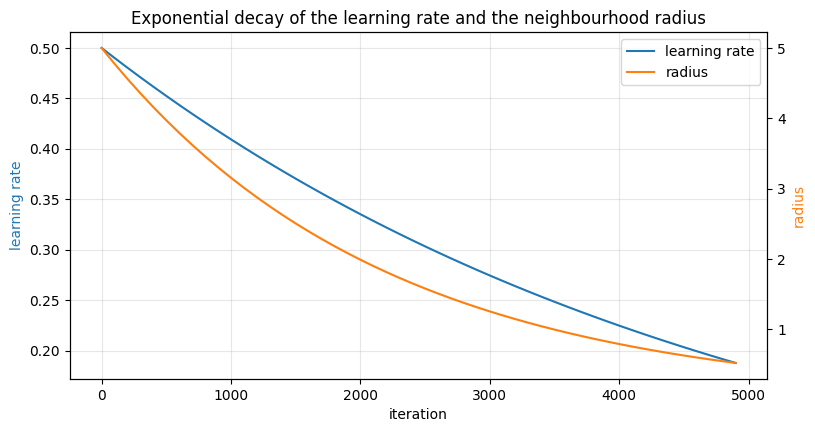

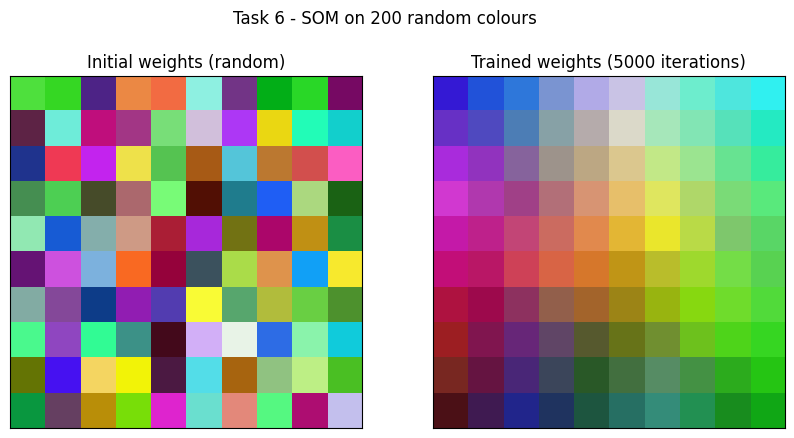

Saved task6_result.png - 20738 bytes


In [13]:
def init_weights(grid_size, seed=SEED):
    """Random starting weights; the same seed always gives the same starting grid."""
    return np.random.default_rng(seed).random((grid_size, grid_size, 3))


def train_som(data, grid_size, iterations, lr_start, radius_start, seed=SEED, radius_end=0.5):
    """Train a SOM and return the trained weights.

    Exponential decay, recalculated at every iteration t:
        learning rate  lr(t)     = lr_start     * exp(-t / iterations)
        radius         radius(t) = radius_start * exp(-t / time_constant)
    time_constant = iterations / ln(radius_start / radius_end), so the radius shrinks
    from radius_start down to radius_end (0.5 = half a neuron spacing) by the end,
    where each neuron is mostly tuned on its own samples.
    """
    weights = init_weights(grid_size, seed)
    rng = np.random.default_rng(seed + 1)          # picks the training samples
    time_constant = iterations / np.log(radius_start / radius_end)

    for t in range(iterations):
        lr = lr_start * np.exp(-t / iterations)
        radius = radius_start * np.exp(-t / time_constant)

        x = data[rng.integers(len(data))]
        bmu = find_bmu(weights, x)
        weights = update_weights(weights, x, bmu, lr, radius)

    return weights


ITERATIONS, LR_START, RADIUS_START = 5000, 0.5, GRID_SIZE / 2
trained = train_som(data, GRID_SIZE, ITERATIONS, LR_START, RADIUS_START)
print("Trained a", GRID_SIZE, "x", GRID_SIZE, "SOM for", ITERATIONS, "iterations")
print("Trained weights shape:", trained.shape)
def train_som(data, grid_size, iterations, lr_start, radius_start, seed=SEED, record_every=100, radius_end=0.5):
    """Same training as 6 (a), but also stores the learning rate and radius
    every `record_every` iterations. Returns (weights, lr_history, radius_history)."""
    weights = init_weights(grid_size, seed)
    rng = np.random.default_rng(seed + 1)
    time_constant = iterations / np.log(radius_start / radius_end)
    lr_history, radius_history = [], []

    for t in range(iterations):
        lr = lr_start * np.exp(-t / iterations)
        radius = radius_start * np.exp(-t / time_constant)

        if t % record_every == 0:
            lr_history.append(lr)
            radius_history.append(radius)

        x = data[rng.integers(len(data))]
        bmu = find_bmu(weights, x)
        weights = update_weights(weights, x, bmu, lr, radius)

    return weights, lr_history, radius_history


trained, lr_history, radius_history = train_som(data, GRID_SIZE, ITERATIONS, LR_START, RADIUS_START)
print("Values stored:", len(lr_history), "(one every 100 of", ITERATIONS, "iterations)")
print("Learning rate: first", round(lr_history[0], 4), "-> last", round(lr_history[-1], 4))
print("Radius       : first", round(radius_history[0], 4), "-> last", round(radius_history[-1], 4))

# Define the missing 'steps' variable
steps = np.arange(len(lr_history)) * 100

fig, ax1 = plt.subplots(figsize=(9, 4.5))
line1 = ax1.plot(steps, lr_history, color="tab:blue", label="learning rate")
ax1.set_xlabel("iteration")
ax1.set_ylabel("learning rate", color="tab:blue")

# The radius is on a much bigger scale, so it gets its own y-axis on the right
ax2 = ax1.twinx()
line2 = ax2.plot(steps, radius_history, color="tab:orange", label="radius")
ax2.set_ylabel("radius", color="tab:orange")

ax1.legend(line1 + line2, [l.get_label() for l in line1 + line2], loc="upper right")
ax1.set_title("Exponential decay of the learning rate and the neighbourhood radius")
ax1.grid(alpha=0.3)
plt.show()
initial = init_weights(GRID_SIZE)          # the exact grid train_som started from

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(initial)
axes[0].set_title("Initial weights (random)")
axes[1].imshow(trained)
axes[1].set_title(f"Trained weights ({ITERATIONS} iterations)")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Task 6 - SOM on 200 random colours")
fig.savefig("task6_result.png", dpi=120, bbox_inches="tight")
plt.show()

import os
print("Saved task6_result.png -", os.path.getsize("task6_result.png"), "bytes")


Task 7: Measuring Training Quality
Topic: Quantization error, recording it during training, measuring the improvement

Task 7 (a)
Write a function quantization_error(data, weights) that returns the average distance between each sample and its own BMU weight vector.
Task 7 (b)
Modify your training function to record the quantization error every 250 iterations.
Task 7 (c)
Plot the error against the iteration number as a line graph with axis labels and a title.
Task 7 (d)
Write code to print the first error, the last error and the percentage reduction between them.


Quantization error, random weights : 0.0662
Quantization error, trained weights: 0.0879
Quantization error recorded 21 times
   iteration     0: 0.0662
   iteration   250: 0.3318
   iteration   500: 0.3578
   iteration   750: 0.2951
   iteration  1000: 0.2919
   ...
   iteration  5000: 0.0879


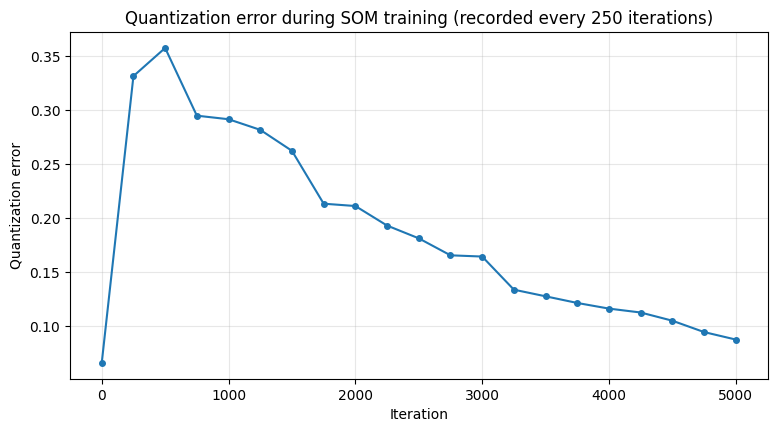

First error (iteration 0)        : 0.0662
Last error  (iteration 5000)     : 0.0879
Percentage reduction             : -32.71%

The error went UP, not down. This is expected for this particular data:
  - the 200 colours are uniformly random, so they fill the whole RGB cube with no clusters;
  - 100 random neurons already spread evenly through that cube, which gives a low error;
  - a SOM keeps neighbouring neurons close together (a 2D sheet bent through a 3D cube),
    so it trades some accuracy for an ordered map. Task 9 uses clustered data, where the error does fall.


In [14]:
def quantization_error(data, weights):
    """Average distance between each sample and the weight vector of its own BMU."""
    flat = weights.reshape(-1, weights.shape[-1])                 # (neurons, 3)
    # (samples, 1, 3) - (1, neurons, 3) -> distance of every sample to every neuron
    dist = np.linalg.norm(data[:, np.newaxis, :] - flat[np.newaxis, :, :], axis=2)
    return dist.min(axis=1).mean()                                 # closest neuron = BMU


print("Quantization error, random weights :", round(quantization_error(data, initial), 4))
print("Quantization error, trained weights:", round(quantization_error(data, trained), 4))
def train_som(data, grid_size, iterations, lr_start, radius_start, seed=SEED,
              record_every=100, qe_every=250, radius_end=0.5):
    """Training from Task 6, now also recording the quantization error every
    `qe_every` iterations (and once more at the very end).
    Returns (weights, history) where history is a dictionary of lists."""
    weights = init_weights(grid_size, seed)
    rng = np.random.default_rng(seed + 1)
    time_constant = iterations / np.log(radius_start / radius_end)
    history = {"lr": [], "radius": [], "qe_iteration": [], "qe": []}

    for t in range(iterations):
        lr = lr_start * np.exp(-t / iterations)
        radius = radius_start * np.exp(-t / time_constant)

        if t % record_every == 0:
            history["lr"].append(lr)
            history["radius"].append(radius)
        if t % qe_every == 0:
            history["qe_iteration"].append(t)
            history["qe"].append(quantization_error(data, weights))

        x = data[rng.integers(len(data))]
        bmu = find_bmu(weights, x)
        weights = update_weights(weights, x, bmu, lr, radius)

    history["qe_iteration"].append(iterations)                     # error after the last step
    history["qe"].append(quantization_error(data, weights))
    return weights, history


trained, history = train_som(data, GRID_SIZE, ITERATIONS, LR_START, RADIUS_START)
print("Quantization error recorded", len(history["qe"]), "times")
for it, qe in list(zip(history["qe_iteration"], history["qe"]))[:5]:
    print(f"   iteration {it:>5}: {qe:.4f}")
print("   ...")
print(f"   iteration {history['qe_iteration'][-1]:>5}: {history['qe'][-1]:.4f}")
plt.figure(figsize=(9, 4.5))
plt.plot(history["qe_iteration"], history["qe"], marker="o", markersize=4)
plt.xlabel("Iteration")
plt.ylabel("Quantization error")
plt.title("Quantization error during SOM training (recorded every 250 iterations)")
plt.grid(alpha=0.3)
plt.show()
first_error, last_error = history["qe"][0], history["qe"][-1]
reduction = (first_error - last_error) / first_error * 100

print(f"First error (iteration 0)        : {first_error:.4f}")
print(f"Last error  (iteration {ITERATIONS})     : {last_error:.4f}")
print(f"Percentage reduction             : {reduction:.2f}%")

if reduction > 0:
    print("\nThe error went down: the trained map represents the colours better than the random one.")
else:
    print("\nThe error went UP, not down. This is expected for this particular data:")
    print("  - the 200 colours are uniformly random, so they fill the whole RGB cube with no clusters;")
    print("  - 100 random neurons already spread evenly through that cube, which gives a low error;")
    print("  - a SOM keeps neighbouring neurons close together (a 2D sheet bent through a 3D cube),")
    print("    so it trades some accuracy for an ordered map. Task 9 uses clustered data, where the error does fall.")


Task 8: Parameter Experiments
Topic: Effect of iterations, grid size and learning rate on the trained map

Task 8 (a)
Write a loop that trains the SOM with iterations of 10, 500 and 5000, and show the three resulting maps side by side with titles.
Task 8 (b)
Write a loop that trains with grid sizes of 5, 10 and 20, and show the three maps side by side.
Task 8 (c)
Write a loop that trains with learning rates of 0.01, 0.5 and 0.9, and show the three maps side by side.
Task 8 (d)
Collect the quantization error of every experiment above and print one summary table (setting name, value, final error) using a loop.


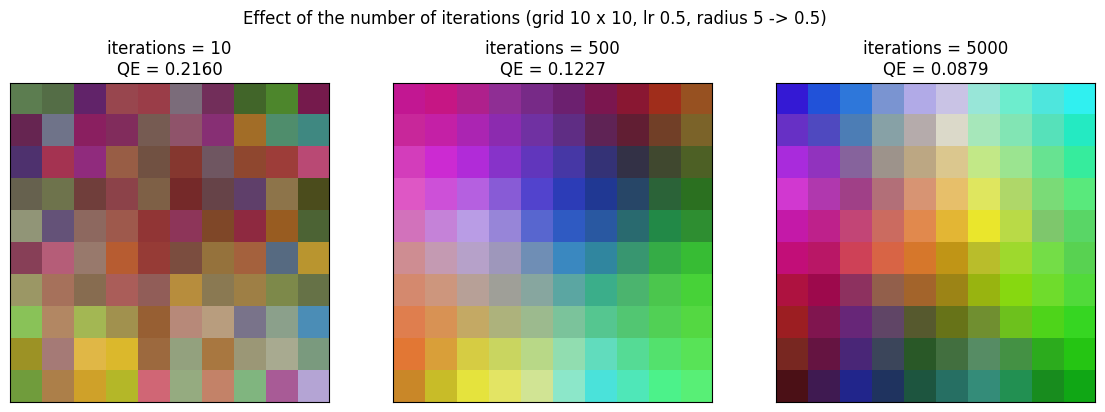

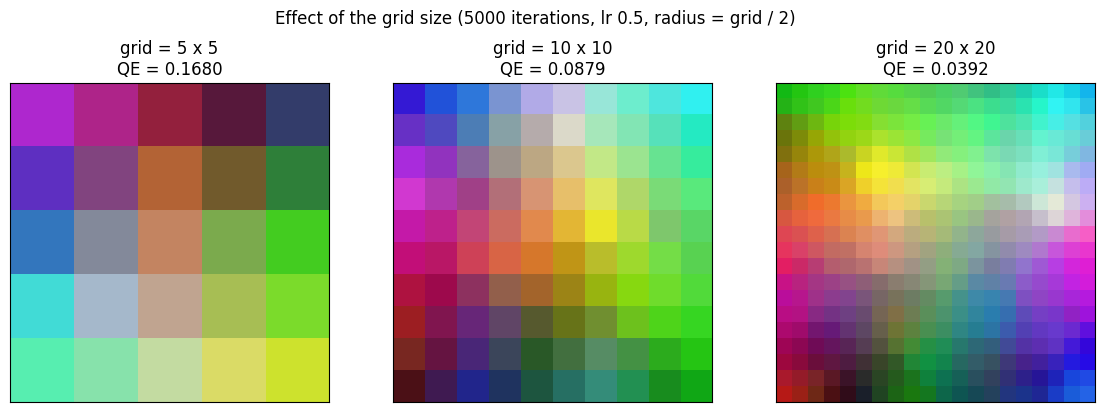

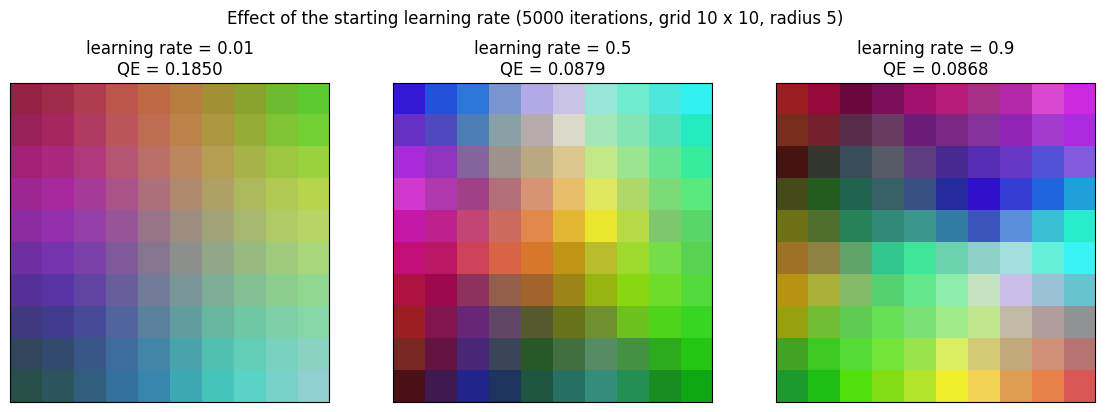

Setting           Value   Final error
-------------------------------------
iterations           10        0.2160
iterations          500        0.1227
iterations         5000        0.0879
grid size             5        0.1680
grid size            10        0.0879
grid size            20        0.0392
learning rate      0.01        0.1850
learning rate       0.5        0.0879
learning rate       0.9        0.0868

Lowest error: grid size = 20 (QE 0.0392)


In [15]:
experiments = []          # (setting name, value, final quantization error) for 8 (d)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, n_iter in zip(axes, [10, 500, 5000]):
    w, hist = train_som(data, 10, n_iter, LR_START, 5)
    experiments.append(("iterations", n_iter, hist["qe"][-1]))
    ax.imshow(w)
    ax.set_title(f"iterations = {n_iter}\nQE = {hist['qe'][-1]:.4f}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Effect of the number of iterations (grid 10 x 10, lr 0.5, radius 5 -> 0.5)")
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, size in zip(axes, [5, 10, 20]):
    w, hist = train_som(data, size, ITERATIONS, LR_START, size / 2)   # radius starts at half the grid
    experiments.append(("grid size", size, hist["qe"][-1]))
    ax.imshow(w)
    ax.set_title(f"grid = {size} x {size}\nQE = {hist['qe'][-1]:.4f}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"Effect of the grid size ({ITERATIONS} iterations, lr 0.5, radius = grid / 2)")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, lr in zip(axes, [0.01, 0.5, 0.9]):
    w, hist = train_som(data, 10, ITERATIONS, lr, 5)
    experiments.append(("learning rate", lr, hist["qe"][-1]))
    ax.imshow(w)
    ax.set_title(f"learning rate = {lr}\nQE = {hist['qe'][-1]:.4f}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"Effect of the starting learning rate ({ITERATIONS} iterations, grid 10 x 10, radius 5)")
plt.show()
print(f"{'Setting':<15}{'Value':>8}{'Final error':>14}")
print("-" * 37)
for name, value, error in experiments:
    print(f"{name:<15}{value:>8}{error:>14.4f}")

best = min(experiments, key=lambda e: e[2])
print(f"\nLowest error: {best[0]} = {best[1]} (QE {best[2]:.4f})")



Task 9: Mini Project with Your Own Data
Topic: Clustered colour data, training a SOM on it and grouping samples by BMU

Task 9 (a)
Write code to generate 100 samples that are close to only three base colors (red, green, blue) by adding small random noise to each, so that every value stays between 0 and 1.
Task 9 (b)
Train a 10 x 10 SOM on this data and display the trained map.
Task 9 (c)
Write code to find the BMU of every sample and group the samples by BMU position using a dictionary.
Task 9 (d)
Print the number of neurons that received at least one sample, and plot the hit map to show how many separate groups appear.


Samples: (100, 3) | min: 0.0 | max: 1.0
   near red  : 28 samples
   near green: 33 samples
   near blue : 39 samples


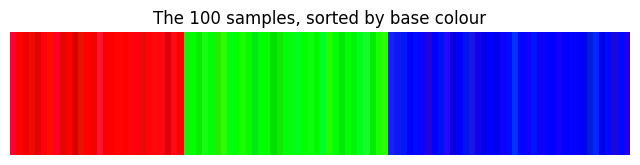

Quantization error: 0.2717 at the start -> 0.0141 after training (94.8% lower)


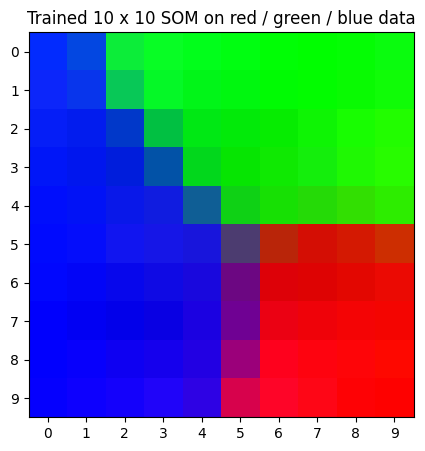

Different BMU positions: 54

BMU        samples   base colours of those samples
(0, 0)           2   blue
(0, 3)           1   green
(0, 4)           2   green
(0, 5)           1   green
(0, 6)           2   green
(0, 7)           7   green
(0, 9)           3   green
(1, 0)           1   blue
(1, 3)           1   green
(1, 5)           1   green
(1, 7)           1   green
(1, 8)           1   green
(2, 4)           2   green
(2, 6)           1   green
(2, 8)           2   green
(2, 9)           1   green
(3, 0)           2   blue
(3, 1)           1   blue
(3, 2)           1   blue
(3, 5)           1   green
(3, 6)           2   green
(3, 7)           1   green
(3, 9)           2   green
(4, 0)           1   blue
(4, 1)           1   blue
(4, 9)           1   green
(5, 0)           3   blue
(5, 2)           1   blue
(5, 3)           1   blue
(6, 0)           2   blue
(6, 4)           1   blue
(6, 6)           1   red
(6, 7)           2   red
(6, 8)           1   red
(6, 9)           3  

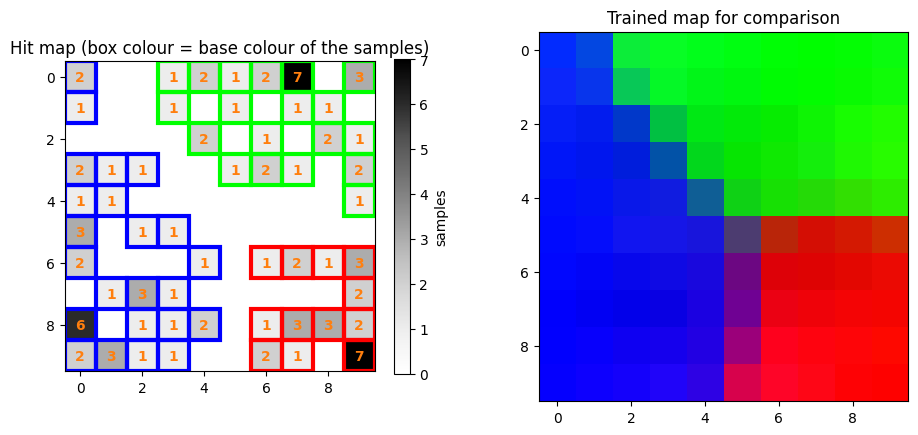

The hit map shows 3 separate groups - one for each base colour - in different corners of the map.


In [16]:
rng9 = np.random.default_rng(SEED)

base_colours = np.array([[1.0, 0.0, 0.0],      # red
                         [0.0, 1.0, 0.0],      # green
                         [0.0, 0.0, 1.0]])     # blue
base_names = ["red", "green", "blue"]

N9 = 100
labels = rng9.integers(0, 3, size=N9)                      # which base colour each sample is near
noise = rng9.normal(0, 0.08, size=(N9, 3))                 # small random noise
data9 = np.clip(base_colours[labels] + noise, 0, 1)        # clip keeps every value in [0, 1]

print("Samples:", data9.shape, "| min:", round(data9.min(), 4), "| max:", round(data9.max(), 4))
for i, name in enumerate(base_names):
    print(f"   near {name:<5}: {np.sum(labels == i)} samples")

order = np.argsort(labels, kind="stable")                  # sort only for the picture
plt.figure(figsize=(8, 1.6))
plt.imshow(data9[order].reshape(1, N9, 3), aspect="auto")
plt.title("The 100 samples, sorted by base colour")
plt.axis("off")
plt.show()
weights9, history9 = train_som(data9, 10, 3000, 0.5, 5)

e0, e1 = history9["qe"][0], history9["qe"][-1]
print(f"Quantization error: {e0:.4f} at the start -> {e1:.4f} after training ({(e0 - e1) / e0 * 100:.1f}% lower)")

plt.figure(figsize=(5, 5))
plt.imshow(weights9)
plt.title("Trained 10 x 10 SOM on red / green / blue data")
plt.xticks(range(10))
plt.yticks(range(10))
plt.show()
groups = {}                          # (row, col) -> list of sample indices
for i, sample in enumerate(data9):
    groups.setdefault(find_bmu(weights9, sample), []).append(i)

print("Different BMU positions:", len(groups))
print(f"\n{'BMU':<10}{'samples':>8}   base colours of those samples")
for position in sorted(groups):
    members = groups[position]
    colours = sorted({base_names[labels[m]] for m in members})
    print(f"{str(position):<10}{len(members):>8}   {', '.join(colours)}")
hit_map9 = np.zeros((10, 10), dtype=int)
for (r, c), members in groups.items():
    hit_map9[r, c] = len(members)

print("Neurons that received at least one sample:", np.count_nonzero(hit_map9), "of 100")

# Which base colour lands where - each BMU only ever holds one colour
for i, name in enumerate(base_names):
    cells = sorted(p for p, m in groups.items() if base_names[labels[m[0]]] == name)
    print(f"   {name:<5} samples -> {len(cells)} neuron(s): {cells}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
im = axes[0].imshow(hit_map9, cmap="Greys")
fig.colorbar(im, ax=axes[0], shrink=0.85, label="samples")
for (r, c), members in groups.items():
    colour = base_colours[labels[members[0]]]
    axes[0].add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor=colour, linewidth=3))
    axes[0].text(c, r, len(members), ha="center", va="center", color="tab:orange", fontweight="bold")
axes[0].set_title("Hit map (box colour = base colour of the samples)")
axes[1].imshow(weights9)
axes[1].set_title("Trained map for comparison")
plt.show()

n_groups = len({base_names[labels[m[0]]] for m in groups.values()})
print(f"The hit map shows {n_groups} separate groups - one for each base colour - in different corners of the map.")